# Cats vs Dogs: Image Classification with CNNs
Students: Valentin Belougne, Simon JENNEQUIN, Thomas DANJOU.

We build a CNN from scratch, try two improvements, and compare them with MobileNetV2 transfer learning (frozen and fine-tuned). Run the cells in order.

## 1. What is a CNN and how does it work?
A **convolutional neural network (CNN)** is a neural network built for grid-shaped data such as images. A plain dense network connects every pixel to every neuron: our 96 × 96 × 3 images already have 27,648 input values, so a single 64-neuron dense layer would need about 1.8 million weights, and it would have to learn the same pattern separately at every position. A CNN avoids both problems with two ideas:

- **Local connections:** each neuron looks at a small patch of the image (3 × 3 pixels here), not the whole image.
- **Weight sharing:** the same small filter slides over the whole image, so a pattern learned in one corner is recognized anywhere.

**Key components**

| Component | What it does | Why it matters |
|---|---|---|
| **Convolutional layer** | Slides learned filters (3 × 3 × channels) over the input. At each position it computes a weighted sum plus a bias. Each filter produces one *feature map* that is high where its pattern appears. | Early layers detect edges and colours; deeper layers combine them into textures, then parts such as ears, eyes and snouts. |
| **Activation function (ReLU)** | Applies $\max(0, x)$ to every value. | Without a nonlinearity, stacked convolutions collapse into a single linear operation and cannot model complex shapes. |
| **Pooling layer (max pooling 2 × 2)** | Keeps the largest value of each 2 × 2 window, halving width and height. | Cuts computation, enlarges what each later neuron "sees", and makes the network tolerant to small shifts. |
| **Fully connected (dense) layer** | After *flattening* the feature maps into one vector, every input connects to every neuron. | Combines all detected features into a decision. Our last layer has one sigmoid neuron that outputs P(dog). |

**How it learns.** For each batch we run a *forward pass* to get predictions, measure the error with a *loss function*, compute the gradient of that loss with respect to every filter weight by *backpropagation*, and let the *optimizer* nudge the weights to reduce the error. We never design the filters by hand: they are learned from the labelled images.

**Our pipeline** (shapes after each block):

```
image 96×96×3
 → [Conv 16 → ReLU → MaxPool]  48×48×16
 → [Conv 32 → ReLU → MaxPool]  24×24×32
 → [Conv 64 → ReLU → MaxPool]  12×12×64
 → [Conv 128 → ReLU → MaxPool]  6×6×128
 → Flatten 4,608 → Dense 64 (ReLU) → Dense 1 (sigmoid) = P(dog)
```

At the end of the notebook we show what the trained network actually computes: its feature maps, and Grad-CAM heatmaps of where it looks.

In [1]:
import os, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_curve, auc
from IPython.display import display

# Keras warns that shuffle=True is ignored for tf.data inputs; our datasets shuffle themselves
warnings.filterwarnings('ignore', message='.*shuffle=True.*')
tf.config.threading.set_intra_op_parallelism_threads(8)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)
SIZE, BATCH, EPOCHS = 96, 100, 15


## 2. Data
**Why resize?** We start with different image dimensions, but our model expects 96 × 96 × 3 inputs. We resize so we can batch images together. We choose 96 pixels to keep CPU training fast; larger inputs preserve more detail but use more memory. Direct resizing can stretch images, so we could add padding instead.

**What did the images look like before resizing?** The raw JPEGs have many different sizes and aspect ratios. We summarize their widths and heights below, so we know how much resizing changes them.

**Why 3 channels?** We keep red, green and blue (RGB), so each pixel has three values.

**Why these quantities?** We follow the requested 80/20 split of the original 2,000 training images: 1,600 for learning and 400 for final testing. We keep the original 1,000 validation images to choose our best weights. We preserve equal numbers of cats and dogs in every split. We give most images to training while reserving unseen examples for evaluation; 80/20 is a practical choice, not a guaranteed optimum.

We update weights on training data, select weights on validation data, and measure final results on test data. We never train on validation or test images. Cat = 0, dog = 1.


,Original train,Train,Validation,Test
Cats,1000,800,500,200
Dogs,1000,800,500,200


Original sizes of all 3000 images (1604 distinct sizes), in pixels:


,Width,Height
mean,406.0,360.0
min,59.0,41.0
50%,447.0,374.0
max,1050.0,768.0


Median aspect ratio (width / height): 1.29


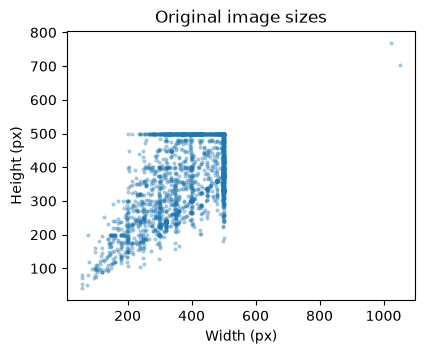

Input shape after resizing: (1600, 96, 96, 3) | pixel range: 0.0 255.0


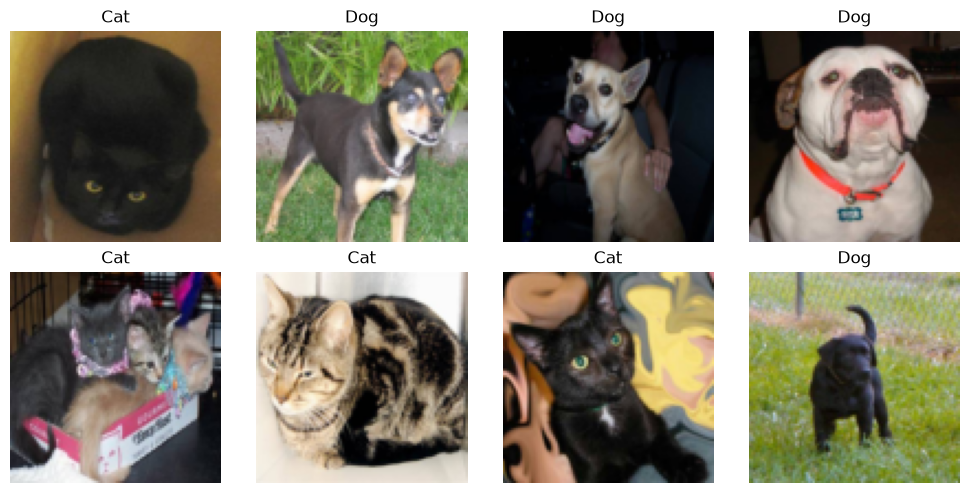

In [2]:
root = Path('data/cats_and_dogs_filtered')
if not root.exists():
    url = 'https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip'
    archive = tf.keras.utils.get_file('cats_and_dogs_filtered.zip', origin=url)
    with zipfile.ZipFile(archive) as z:
        z.extractall('data')

def load_images(folder):
    paths = sorted((root / folder).glob('*/*.jpg'))
    images = [np.asarray(Image.open(p).convert('RGB').resize((SIZE, SIZE), Image.Resampling.BILINEAR)) for p in paths]
    labels = [int(p.parent.name == 'dogs') for p in paths]
    return np.array(images, dtype='float32'), np.array(labels, dtype='float32')

x, y = load_images('train')
x_val, y_val = load_images('validation')
train_ids, test_ids = train_test_split(np.arange(len(y)), test_size=.2, stratify=y, random_state=42)
x_train, y_train = x[np.sort(train_ids)], y[np.sort(train_ids)]
x_test, y_test = x[np.sort(test_ids)], y[np.sort(test_ids)]

display(pd.DataFrame({name: np.bincount(labels.astype(int)) for name, labels in
                     [('Original train', y), ('Train', y_train), ('Validation', y_val), ('Test', y_test)]}, index=['Cats', 'Dogs']))
sizes = pd.DataFrame([Image.open(p).size for p in sorted(root.glob('*/*/*.jpg'))], columns=['Width', 'Height'])
print(f'Original sizes of all {len(sizes)} images ({len(sizes.value_counts())} distinct sizes), in pixels:')
display(sizes.describe().loc[['mean', 'min', '50%', 'max']].round(0))
print('Median aspect ratio (width / height):', round((sizes.Width / sizes.Height).median(), 2))
plt.figure(figsize=(4.5, 3.5)); plt.scatter(sizes.Width, sizes.Height, s=4, alpha=.3)
plt.title('Original image sizes'); plt.xlabel('Width (px)'); plt.ylabel('Height (px)'); plt.show()

print('Input shape after resizing:', x_train.shape, '| pixel range:', x_train.min(), x_train.max())

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, i in zip(axes.flat, np.random.default_rng(42).choice(len(y_train), 8, replace=False)):
    ax.imshow(x_train[i].astype('uint8')); ax.set_title(['Cat', 'Dog'][int(y_train[i])]); ax.axis('off')
plt.tight_layout(); plt.show()

def dataset(x, y, shuffle=False, augment=None):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle: ds = ds.shuffle(len(y), seed=42)
    ds = ds.batch(BATCH)
    if augment is not None: ds = ds.map(lambda x, y: (augment(x, training=True), y))
    options = tf.data.Options(); options.threading.private_threadpool_size = 2
    return ds.with_options(options).prefetch(1)
train_ds, val_ds = dataset(x_train, y_train, True), dataset(x_val, y_val)


## 3. Model
We use **four convolutional blocks**, with **16, 32, 64 and 128 filters**, not three layers. We gradually increase the number of feature maps as pooling reduces image size. We start with a small model for fast training; these filter counts are a design choice, not a proven optimum.

| Layer | Why we use it |
|---|---|
| Rescaling | We divide pixels by 255, changing their range from [0, 255] to [0, 1] for a smaller, consistent input scale. |
| Conv2D, 3 × 3 | We learn local patterns with small filters and relatively few weights. Each filter covers all input channels and produces one feature map. |
| ReLU | We use max(0, x) to introduce nonlinearity, so we can learn more than a linear relationship. |
| MaxPooling, 2 × 2 | We keep the strongest value in each region and halve width and height. |
| Flatten | We turn the final 6 × 6 × 128 feature maps into 4,608 numbers. We do not learn weights here. |
| Dense(64), ReLU | We combine features into 64 learned values; we choose a small hidden layer to limit model size. |
| Dense(1), sigmoid | We output an estimated probability of dog between 0 and 1; we predict dog at 0.5 or above. |

**Why $(3×3×C_{in}+1)×C_{out}$?** We need nine weights per input channel for each 3 × 3 filter, plus **one bias per filter**. We multiply by the number of output filters. For our first layer: $(3×3×3+1)×16=448$. We omit the bias in our batch-normalized convolutions, so their formula has no +1.

For dense layers, we count $(n_{in}+1)×n_{out}$. Our Dense(64) therefore has $(4608+1)×64=294,976$ parameters. We count **392,481** parameters in the baseline altogether.

We use **Adam (0.001)** as a practical adaptive optimizer. We use **binary cross-entropy** because we have two classes and one sigmoid probability. We did not compare optimizers, so we do not claim Adam is the best choice.


In [3]:
from tensorflow.keras import layers

def cnn():
    return tf.keras.Sequential([
        layers.Input((SIZE, SIZE, 3)),
        layers.Rescaling(1/255),
        layers.Conv2D(16, 3, padding='same'), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding='same'), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same'), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same'), layers.ReLU(), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

def regularized_cnn():
    # momentum=.9: the default .99 keeps ~9% of its initial statistics after our 240 updates
    bn = lambda: layers.BatchNormalization(momentum=.9)
    return tf.keras.Sequential([
        layers.Input((SIZE, SIZE, 3)),
        layers.Rescaling(1/255),
        layers.Conv2D(16, 3, padding='same', use_bias=False), bn(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding='same', use_bias=False), bn(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', use_bias=False), bn(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', use_bias=False), bn(), layers.ReLU(), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dropout(.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
baseline = cnn()
parameters = [28*16, 145*32, 289*64, 577*128, 4609*64, 65]
print('Conv1–4, Dense, Output:', parameters)
print('Total:', sum(parameters))
assert sum(parameters) == baseline.count_params()
baseline.summary()


Conv1–4, Dense, Output: [448, 4640, 18496, 73856, 294976, 65]
Total: 392481


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 96, 96, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,481 (1.50 MB)

 Trainable params: 392,481 (1.50 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Training
**Batch size = 100:** we process 100 images before each weight update. We follow the assignment; it also keeps memory use manageable. With 1,600 training images, we make 16 updates per epoch.

**Epochs = 15:** we pass through the training data fifteen times, giving 240 updates. We take the top of the requested 5–15 range: with 10 epochs our baseline was still improving and our regularized models had not finished learning. More epochs can help learning but may increase overfitting, so we keep the best epoch rather than the last one.

We plot training and validation accuracy/loss after each epoch and keep the weights with the lowest validation loss. We use the test set only after training all models.

Epoch 1/15


16/16 - 2s - 98ms/step - accuracy: 0.4863 - loss: 0.6941 - val_accuracy: 0.5000 - val_loss: 0.6908


Epoch 2/15


16/16 - 1s - 58ms/step - accuracy: 0.5181 - loss: 0.6896 - val_accuracy: 0.5050 - val_loss: 0.6810


Epoch 3/15


...

16/16 - 1s - 60ms/step - accuracy: 0.7937 - loss: 0.4334 - val_accuracy: 0.7240 - val_loss: 0.5534


Epoch 14/15


16/16 - 1s - 60ms/step - accuracy: 0.8325 - loss: 0.3816 - val_accuracy: 0.7190 - val_loss: 0.5701


Epoch 15/15


16/16 - 1s - 60ms/step - accuracy: 0.8450 - loss: 0.3485 - val_accuracy: 0.7330 - val_loss: 0.5640


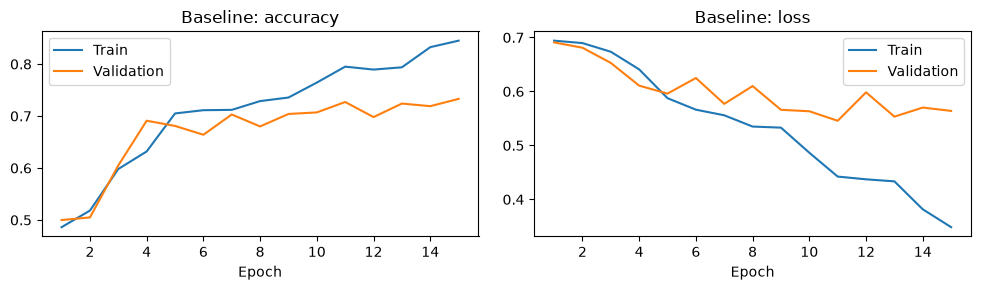

In [4]:
models, histories, val_losses = {}, {}, {}
def fit(name, model, training, validation, lr=.001, epochs=EPOCHS):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])

    best = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=epochs, restore_best_weights=True)
    
    h = model.fit(training, validation_data=validation, epochs=epochs, verbose=2, callbacks=[best]).history
    models[name], histories[name] = model, h
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(range(1, epochs+1), h[metric], label='Train')
        ax.plot(range(1, epochs+1), h['val_'+metric], label='Validation')
        ax.set(title=f'{name}: {metric}', xlabel='Epoch'); ax.legend()
    plt.tight_layout(); plt.show()
fit('Baseline', baseline, train_ds, val_ds)


**Baseline:** we reach our lowest validation loss at epoch 11 (0.546, 72.7% validation accuracy), and we keep those weights. After that, training accuracy keeps rising to 84.5% while validation loss stops improving and fluctuates around 0.55–0.60: the model starts to memorize the training images. We use this as the reference for the improvements below.

## 5. Improvements
We try each intervention separately. Augmentation keeps the same CNN and adds flips, rotations and zooms. We augment training and validation as requested, but never test. We also compare clean validation loss.

**What is a regularized model?** We add mechanisms that aim to reduce memorization and improve performance on unseen images. Here, we try dropout + batch normalization together, without augmentation.

**Why dropout?** During training, we randomly zero 30% of the flattened features before the dense layer. We discourage dependence on particular features. We disable dropout during validation and testing. Too much dropout can make learning harder: our first version also dropped 15% after every block and 50% before the output, and it learned too slowly for 15 epochs.

**Why batch normalization?** We normalize convolution outputs using batch statistics during training and moving averages of those statistics during inference. We aim to stabilize and speed up learning; it does not guarantee better results. **Why momentum = 0.9?** Keras updates the moving averages with momentum 0.99 by default, so after our 240 updates they still hold about 9% (0.99²⁴⁰) of their initial values. Our first version used that default: at validation time it normalized with the wrong statistics and predicted only one class (50% accuracy). With 0.9, the moving averages follow the real statistics within a few dozen updates.

Epoch 1/15


16/16 - 3s - 173ms/step - accuracy: 0.4988 - loss: 0.6946 - val_accuracy: 0.5530 - val_loss: 0.6926


Epoch 2/15


16/16 - 2s - 143ms/step - accuracy: 0.5231 - loss: 0.6904 - val_accuracy: 0.5170 - val_loss: 0.6818


Epoch 3/15


...

16/16 - 2s - 143ms/step - accuracy: 0.7362 - loss: 0.5383 - val_accuracy: 0.7150 - val_loss: 0.5532


Epoch 14/15


16/16 - 2s - 147ms/step - accuracy: 0.7625 - loss: 0.4968 - val_accuracy: 0.7040 - val_loss: 0.5592


Epoch 15/15


16/16 - 2s - 146ms/step - accuracy: 0.7619 - loss: 0.4968 - val_accuracy: 0.7170 - val_loss: 0.5292


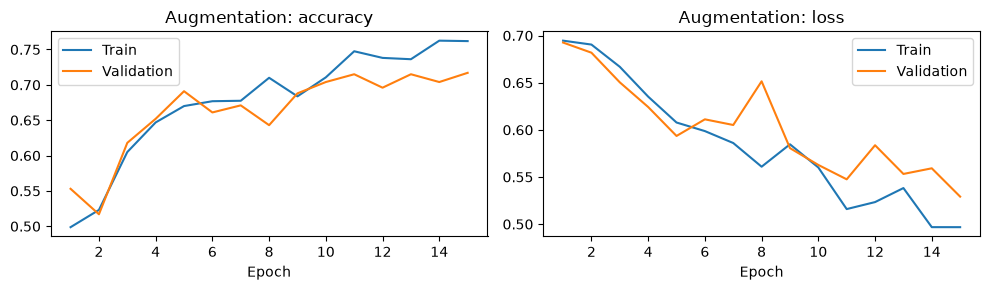

Epoch 1/15


16/16 - 4s - 220ms/step - accuracy: 0.5494 - loss: 0.9587 - val_accuracy: 0.5050 - val_loss: 0.6930


Epoch 2/15


16/16 - 3s - 168ms/step - accuracy: 0.6019 - loss: 0.6559 - val_accuracy: 0.5000 - val_loss: 0.7255


Epoch 3/15


...

16/16 - 3s - 163ms/step - accuracy: 0.9669 - loss: 0.1261 - val_accuracy: 0.7450 - val_loss: 0.5527


Epoch 14/15


16/16 - 3s - 168ms/step - accuracy: 0.9712 - loss: 0.1074 - val_accuracy: 0.7050 - val_loss: 0.6908


Epoch 15/15


16/16 - 3s - 163ms/step - accuracy: 0.9663 - loss: 0.1084 - val_accuracy: 0.6680 - val_loss: 0.8891


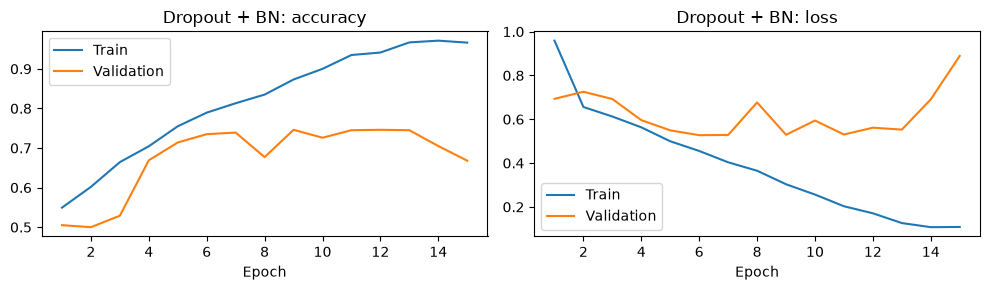

In [5]:
augment = tf.keras.Sequential([tf.keras.layers.RandomFlip('horizontal', seed=42),
                               tf.keras.layers.RandomRotation(.05, seed=43),
                               tf.keras.layers.RandomZoom(.1, seed=44)])
tf.keras.utils.set_random_seed(42)
fit('Augmentation', cnn(), dataset(x_train, y_train, True, augment), dataset(x_val, y_val, augment=augment))
tf.keras.utils.set_random_seed(42)
fit('Dropout + BN', regularized_cnn(), train_ds, val_ds)


**Improvements takeaway:** augmentation reaches its best validation loss at the last epoch (0.529 on augmented validation, 71.7% accuracy). Its train/validation gap stays small (76.2% vs 71.7%), so it fits the training set less tightly, as intended, but it learns more slowly; 15 epochs are not enough for it to pull ahead of the baseline.

Dropout + batch normalization learns much faster: its best epoch is 6, with 73.5% validation accuracy and a validation loss of 0.527, both slightly better than the baseline (72.7%, 0.546). After that it overfits strongly (96.6% train vs 66.8% validation at epoch 15), and we keep the epoch 6 weights. Batch normalization speeds up learning more than dropout slows it down, so this model still memorizes; stronger dropout or augmentation would be the next step.

*Note:* multi-threaded CPU training is not perfectly deterministic, so the dropout + batch-normalization numbers move by about one percentage point between reruns even with a fixed seed.

## Bonus: transfer learning
**Step A, feature extraction.** We freeze ImageNet-pretrained MobileNetV2 and train only a new sigmoid head on top of it. We scale pixels to [−1, 1] as MobileNetV2 expects, and we compute the frozen features once to save time.

Epoch 1/15


16/16 - 0s - 12ms/step - accuracy: 0.7000 - loss: 0.5648 - val_accuracy: 0.8910 - val_loss: 0.3167


Epoch 2/15


16/16 - 0s - 1ms/step - accuracy: 0.9306 - loss: 0.2265 - val_accuracy: 0.9440 - val_loss: 0.1928


Epoch 3/15


...

16/16 - 0s - 1ms/step - accuracy: 0.9812 - loss: 0.0618 - val_accuracy: 0.9600 - val_loss: 0.1131


Epoch 14/15


16/16 - 0s - 1ms/step - accuracy: 0.9825 - loss: 0.0583 - val_accuracy: 0.9610 - val_loss: 0.1125


Epoch 15/15


16/16 - 0s - 1ms/step - accuracy: 0.9844 - loss: 0.0548 - val_accuracy: 0.9620 - val_loss: 0.1121


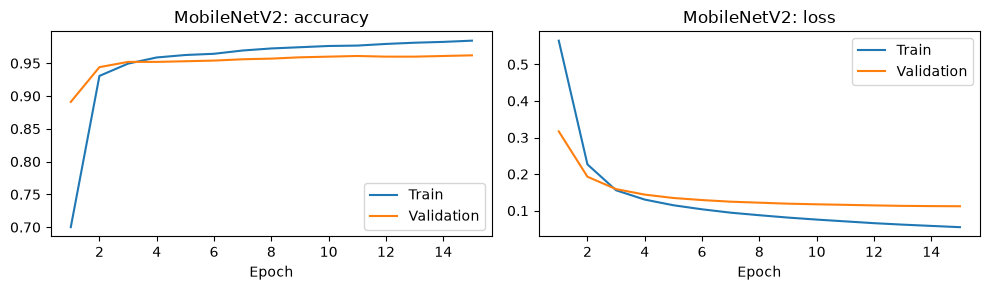

In [6]:
tf.keras.utils.set_random_seed(42)
base = tf.keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights='imagenet', pooling='avg')
base.trainable = False
def features(x):
    return base.predict(tf.keras.applications.mobilenet_v2.preprocess_input(x.copy()), batch_size=BATCH, verbose=0)
head = tf.keras.Sequential([tf.keras.layers.Input((1280,)), tf.keras.layers.Dense(1, activation='sigmoid')])
fit('MobileNetV2', head, dataset(features(x_train), y_train, True), dataset(features(x_val), y_val))
inputs = tf.keras.Input((SIZE, SIZE, 3))
models['MobileNetV2'] = tf.keras.Model(inputs, head(base(tf.keras.layers.Rescaling(1/127.5, offset=-1)(inputs), training=False)))
models['MobileNetV2'].compile(loss='binary_crossentropy', metrics=['accuracy'])


**Step B, fine-tuning.** We then unfreeze the last 30 layers of MobileNetV2 (its top inverted-residual blocks and final 1 × 1 convolution) and train them together with the head, starting from the Step A weights. We use a learning rate 100 times smaller (0.00001) so we adapt the pretrained filters to cats and dogs without destroying them. We keep the batch-normalization layers in inference mode (`training=False`) so their ImageNet statistics stay intact. We copy the base and head first, so the frozen model from Step A stays available for comparison.

Trainable parameters: 1,527,361 of 2,259,265
Epoch 1/5


16/16 - 5s - 308ms/step - accuracy: 0.9844 - loss: 0.0509 - val_accuracy: 0.9640 - val_loss: 0.1102


Epoch 2/5


16/16 - 3s - 156ms/step - accuracy: 0.9950 - loss: 0.0321 - val_accuracy: 0.9620 - val_loss: 0.1099


Epoch 3/5


16/16 - 2s - 155ms/step - accuracy: 0.9969 - loss: 0.0222 - val_accuracy: 0.9630 - val_loss: 0.1125


Epoch 4/5


16/16 - 2s - 156ms/step - accuracy: 0.9987 - loss: 0.0157 - val_accuracy: 0.9640 - val_loss: 0.1149


Epoch 5/5


16/16 - 2s - 155ms/step - accuracy: 1.0000 - loss: 0.0116 - val_accuracy: 0.9640 - val_loss: 0.1170


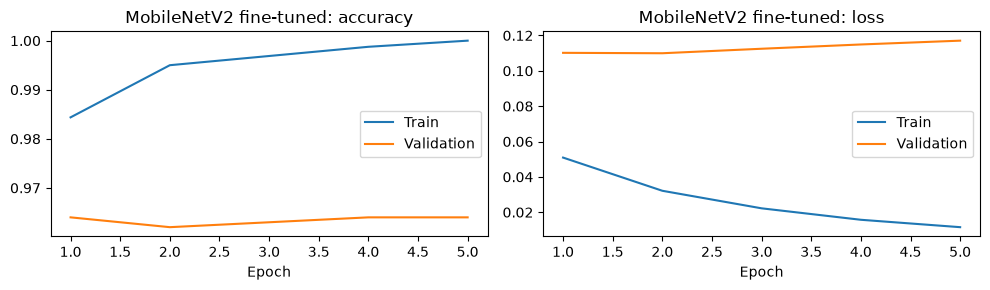

In [7]:
tf.keras.utils.set_random_seed(42)
tuned_base = tf.keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights='imagenet', pooling='avg')
for layer in tuned_base.layers[:-30]:
    layer.trainable = False
tuned_head = tf.keras.models.clone_model(head)
tuned_head.set_weights(head.get_weights())
inputs = tf.keras.Input((SIZE, SIZE, 3))
tuned = tf.keras.Model(inputs, tuned_head(tuned_base(tf.keras.layers.Rescaling(1/127.5, offset=-1)(inputs), training=False)))
print(f'Trainable parameters: {sum(w.numpy().size for w in tuned.trainable_weights):,} of {tuned.count_params():,}')
fit('MobileNetV2 fine-tuned', tuned, train_ds, val_ds, lr=1e-5, epochs=5)

## 6. Test results
We choose a model using clean validation loss before looking at test results. We predict dog when its probability is at least 0.5. Precision measures correct dog predictions; recall measures recovered dogs; F1 balances both.


Our validation-selected model: MobileNetV2 fine-tuned


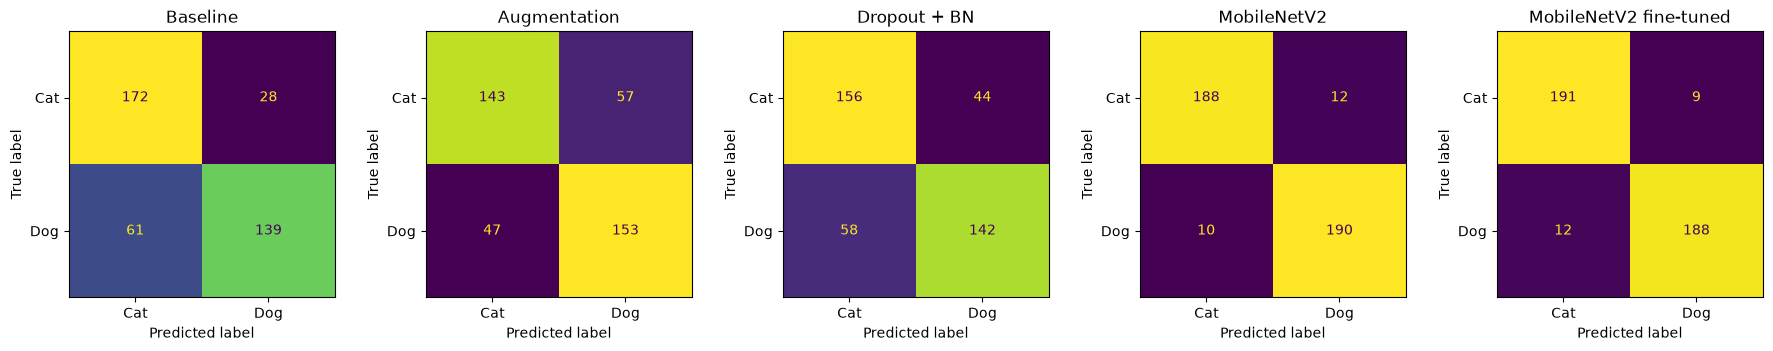

,Accuracy,Precision,Recall,F1
Model,,,,
Baseline,0.778,0.832,0.695,0.757
Augmentation,0.740,0.729,0.765,0.746
Dropout + BN,0.745,0.763,0.710,0.736
MobileNetV2,0.945,0.941,0.950,0.945
MobileNetV2 fine-tuned,0.948,0.954,0.940,0.947


Baseline: final train 84.5%, validation 73.3%; best epoch 11
Augmentation: final train 76.2%, validation 71.7%; best epoch 15
Dropout + BN: final train 96.6%, validation 66.8%; best epoch 6
MobileNetV2: final train 98.4%, validation 96.2%; best epoch 15
MobileNetV2 fine-tuned: final train 100.0%, validation 96.4%; best epoch 2


In [8]:
val_losses = {name: model.evaluate(val_ds, verbose=0)[0] for name, model in models.items()}
selected = min(val_losses, key=val_losses.get)
print('Our validation-selected model:', selected)
results, probabilities = [], {}
fig, axes = plt.subplots(1, len(models), figsize=(3.6*len(models), 3.4))
for ax, (name, model) in zip(axes, models.items()):
    probabilities[name] = model.predict(dataset(x_test, y_test), verbose=0).ravel()
    prediction = (probabilities[name] >= .5).astype(int)
    report = classification_report(y_test, prediction, target_names=['Cat', 'Dog'], output_dict=True, zero_division=0)
    results.append({'Model': name, 'Accuracy': report['accuracy'], 'Precision': report['Dog']['precision'],
                    'Recall': report['Dog']['recall'], 'F1': report['Dog']['f1-score']})
    ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=['Cat', 'Dog'], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
display(pd.DataFrame(results).set_index('Model').round(3))
for name, h in histories.items():
    print(f"{name}: final train {h['accuracy'][-1]:.1%}, validation {h['val_accuracy'][-1]:.1%}; best epoch {np.argmin(h['val_loss'])+1}")


### ROC curves
The confusion matrices use a fixed 0.5 threshold. A **ROC curve** shows every threshold at once: the true-positive rate (dogs found) against the false-positive rate (cats wrongly called dogs). The **AUC** (area under the curve) is the probability that the model gives a random dog a higher score than a random cat: 0.5 is guessing, 1.0 is perfect.

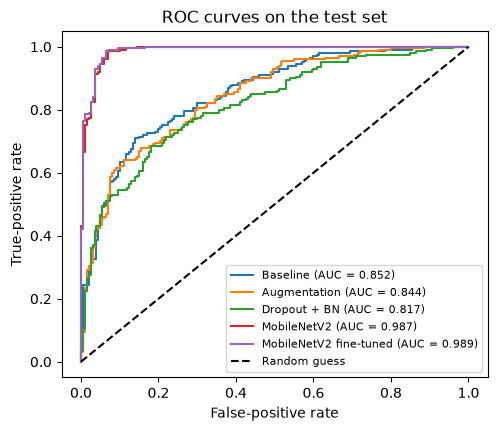

In [9]:
plt.figure(figsize=(5.5, 4.5))
for name, p in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False-positive rate'); plt.ylabel('True-positive rate'); plt.title('ROC curves on the test set')
plt.legend(fontsize=8); plt.show()

### Error analysis
We look at the test images our validation-selected model gets wrong, starting with the ones it was most confident about. P(dog) is the predicted probability; above 0.5 means it answered "dog".

MobileNetV2 fine-tuned: 21 errors out of 400 test images


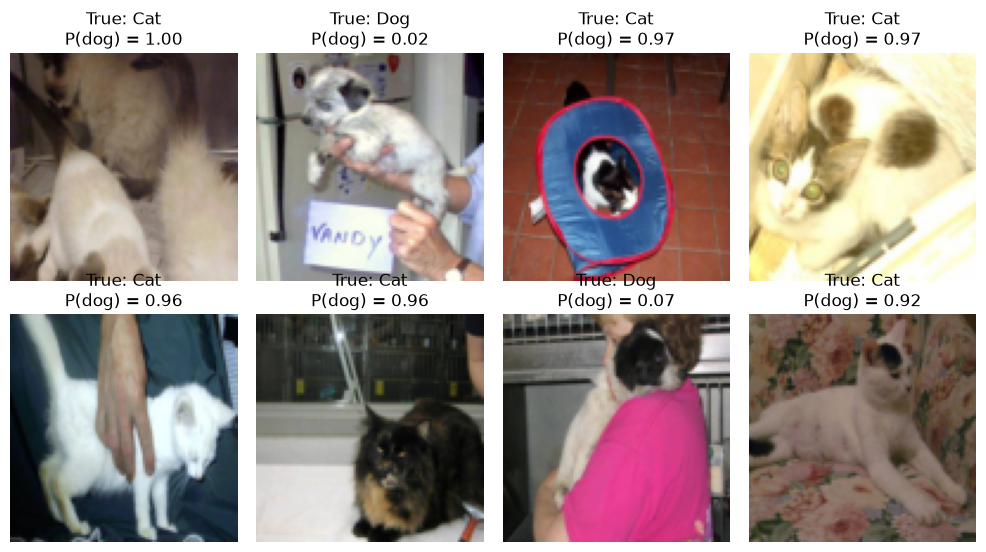

In [10]:
p = probabilities[selected]
wrong = np.flatnonzero((p >= .5) != y_test)
wrong = wrong[np.argsort(-abs(p[wrong] - .5))]
print(f'{selected}: {len(wrong)} errors out of {len(y_test)} test images')
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong[:8]):
    ax.imshow(x_test[i].astype('uint8')); ax.set_title(f"True: {['Cat', 'Dog'][int(y_test[i])]}\nP(dog) = {p[i]:.2f}")
plt.tight_layout(); plt.show()

### Inside our CNN: feature maps and Grad-CAM
**Feature maps.** We feed one test image to our baseline CNN and plot some outputs of its convolutional blocks. The first block reacts to simple edges and colour contrasts; the third block works at a coarser 24 × 24 resolution and reacts to larger, more abstract patterns.

**Grad-CAM** (Selvaraju et al., 2017) shows *where* the CNN looks when it decides. We take the feature maps of the last convolutional block (12 × 12 × 128), weight each map by how much it increases the score of the predicted class (the average gradient), sum them, keep the positive part and upscale it onto the image. Red areas pushed the decision the most.

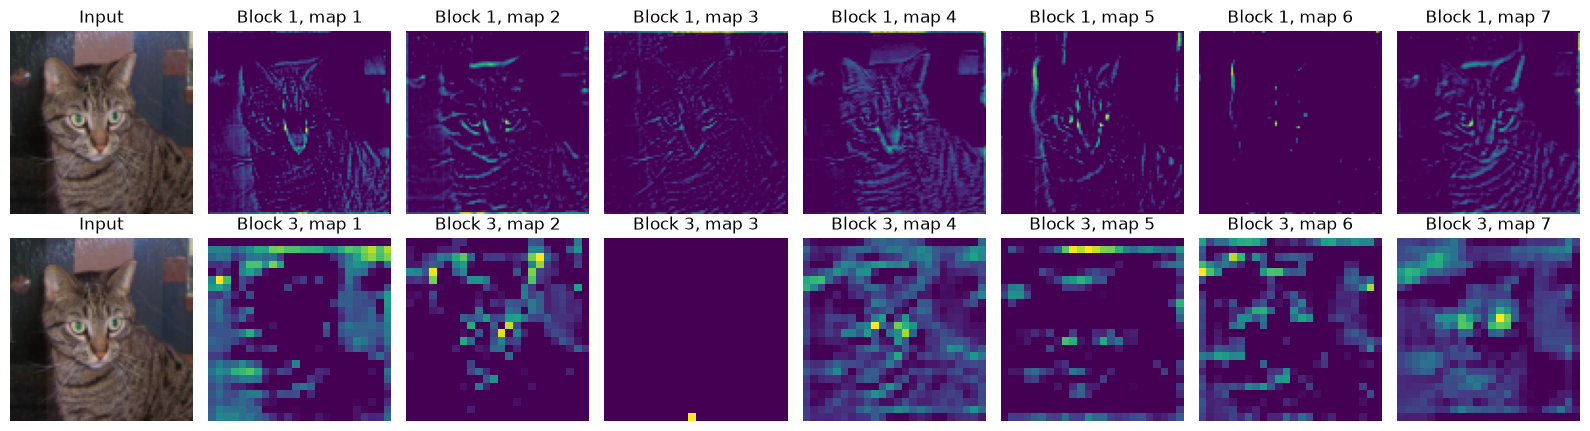

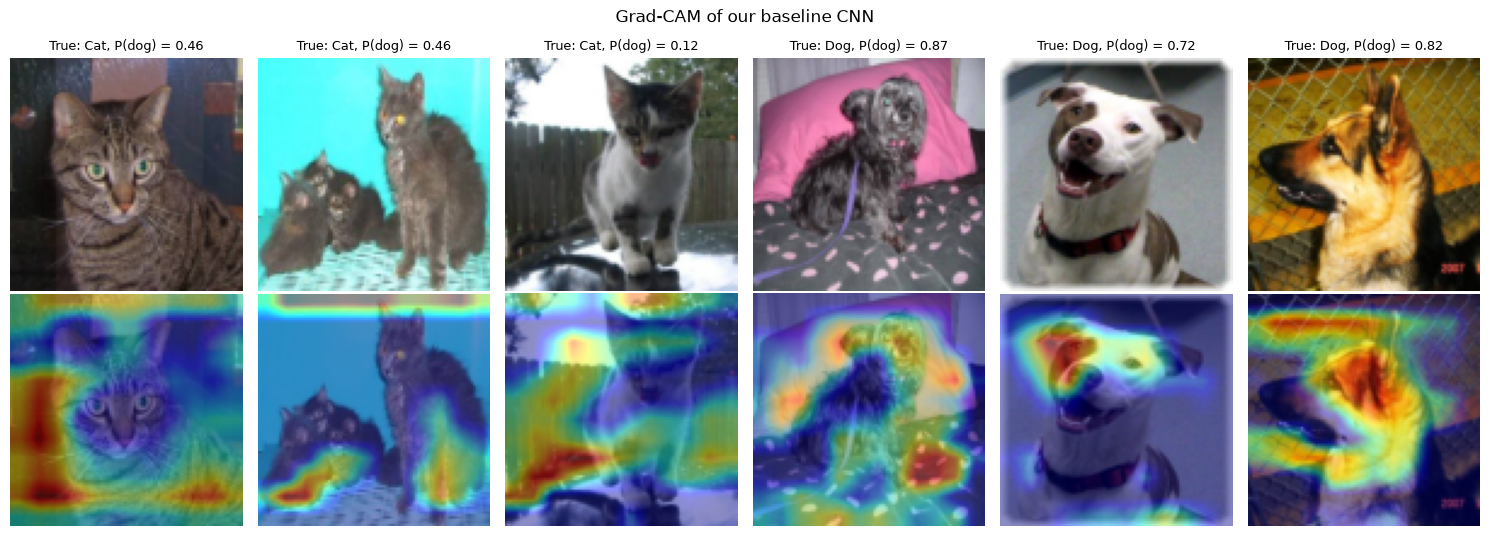

In [11]:
image = x_test[0]
activations, x_ = [], image[None]
for layer in baseline.layers:
    x_ = layer(x_)
    if isinstance(layer, layers.ReLU):
        activations.append(x_[0].numpy())
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, block in enumerate([0, 2]):
    axes[row, 0].imshow(image.astype('uint8')); axes[row, 0].set_title('Input')
    for k, ax in enumerate(axes[row, 1:]):
        ax.imshow(activations[block][..., k], cmap='viridis'); ax.set_title(f'Block {block+1}, map {k+1}')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()

def grad_cam(model, image):
    # we replay the layers one by one to keep the last ReLU feature maps and their gradients
    last = max(i for i, layer in enumerate(model.layers) if isinstance(layer, layers.ReLU))
    x = tf.convert_to_tensor(image[None])
    with tf.GradientTape() as tape:
        for i, layer in enumerate(model.layers):
            x = layer(x)
            if i == last:
                maps = x
                tape.watch(maps)
        dog = x[0, 0]
        score = dog if dog >= .5 else 1 - dog  # score of the predicted class
    weights = tf.reduce_mean(tape.gradient(score, maps)[0], axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(maps[0] * weights, axis=-1))
    cam = tf.image.resize((cam / (tf.reduce_max(cam) + 1e-8))[..., None], (SIZE, SIZE))[..., 0]
    return cam.numpy(), float(dog)

picks = np.r_[np.flatnonzero(y_test == 0)[:3], np.flatnonzero(y_test == 1)[:3]]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for col, i in enumerate(picks):
    cam, dog = grad_cam(baseline, x_test[i])
    axes[0, col].imshow(x_test[i].astype('uint8'))
    axes[0, col].set_title(f"True: {['Cat', 'Dog'][int(y_test[i])]}, P(dog) = {dog:.2f}", fontsize=9)
    axes[1, col].imshow(x_test[i].astype('uint8')); axes[1, col].imshow(cam, cmap='jet', alpha=.45)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('Grad-CAM of our baseline CNN'); plt.tight_layout(); plt.show()